In [ ]:

import numpy as np
import heapq


p, q, M = 0.002, 0.30, 20000
U0 = 100
delta0, kW, kR, Wok = 0.003, 1.0, 0.5, 0.75
a, mu, K = 0.0005, 2.0, 60
theta, lote, D = 0.7, 2, 5
c0 = 4
T, H, dt = 100, 1, 0.1
T_PICO, WARMUP = 720.0, 120.0
SEED = 42



def simular_des(lam, c, rng):
    """Simula M/M/c/K durante T_PICO segundos. Devuelve (W promedio, fracción rechazada)."""
    if lam <= 0:
        return 1 / mu, 0.0
    t = 0.0
    eventos = []  # (tiempo, tipo, id)
    heapq.heappush(eventos, (rng.exponential(1 / lam), "llegada", 0))
    en_sistema = 0
    ocupados = 0
    cola = []
    llegada_de = {}
    sig_id = 1
    tiempos = []
    llegadas_medidas = 0
    rechazos = 0

    while eventos:
        t, tipo, cid = heapq.heappop(eventos)
        if t > T_PICO:
            break
        if tipo == "llegada":
            # programar la siguiente llegada
            heapq.heappush(eventos, (t + rng.exponential(1 / lam), "llegada", sig_id))
            sig_id += 1
            if t > WARMUP:
                llegadas_medidas += 1
            if en_sistema >= K:
                if t > WARMUP:
                    rechazos += 1
                continue
            en_sistema += 1
            llegada_de[cid] = t
            if ocupados < c:
                ocupados += 1
                heapq.heappush(eventos, (t + rng.exponential(1 / mu), "salida", cid))
            else:
                cola.append(cid)
        else:  # salida
            en_sistema -= 1
            if t > WARMUP:
                tiempos.append(t - llegada_de[cid])
            del llegada_de[cid]
            if cola:
                nid = cola.pop(0)
                heapq.heappush(eventos, (t + rng.exponential(1 / mu), "salida", nid))
            else:
                ocupados -= 1

    W = np.mean(tiempos) if tiempos else 1 / mu
    r = rechazos / llegadas_medidas if llegadas_medidas > 0 else 0.0
    return W, r


# ---------------- Capa SD + acoplamiento ----------------
def correr(H=H, c_ini=c0, feedback=True, seed=SEED):
    rng = np.random.default_rng(seed)
    kw = kW if feedback else 0.0
    kr = kR if feedback else 0.0

    n = int(round(T / dt))
    t_hist, U_hist, c_hist, W_hist, r_hist = [], [], [], [], []
    U, c = float(U0), c_ini
    W, r = 1 / mu, 0.0
    pendiente = False
    t_llegada = None
    pedidos = []
    prox_intercambio = 0.0

    for i in range(n + 1):
        t = i * dt

        # llegada de servidores (evento de tiempo)
        if pendiente and t >= t_llegada:
            c += lote
            pendiente = False

        # política de autoescalado
        rho_pred = a * U / (c * mu)
        if rho_pred > theta and not pendiente:
            pendiente = True
            t_llegada = t + D
            pedidos.append(t)

        # intercambio con el DES cada H días
        if t >= prox_intercambio - 1e-9:
            W, r = simular_des(a * U, c, rng)
            prox_intercambio += H

        t_hist.append(t); U_hist.append(U); c_hist.append(c)
        W_hist.append(W); r_hist.append(r)

        # paso de Euler
        delta = delta0 + kw * max(0.0, W - Wok) + kr * r
        dU = (p + q * U / M) * (M - U) - delta * U
        U = U + dt * dU

    return dict(t=np.array(t_hist), U=np.array(U_hist), c=np.array(c_hist),
                W=np.array(W_hist), r=np.array(r_hist), pedidos=pedidos)

U(100)              = 19801.3
Servidores finales  = 8
Latencia máxima     = 1.369 s
Rechazo máximo      = 0.0000
Pedidos (día)       = [15.9, 26.7]

Cascada (kW = kR = 0):
U(100) = 19801.3, c = 8, Wmax = 4.389 s, rmax = 0.0239
Pedidos (día) = [15.9, 20.9]


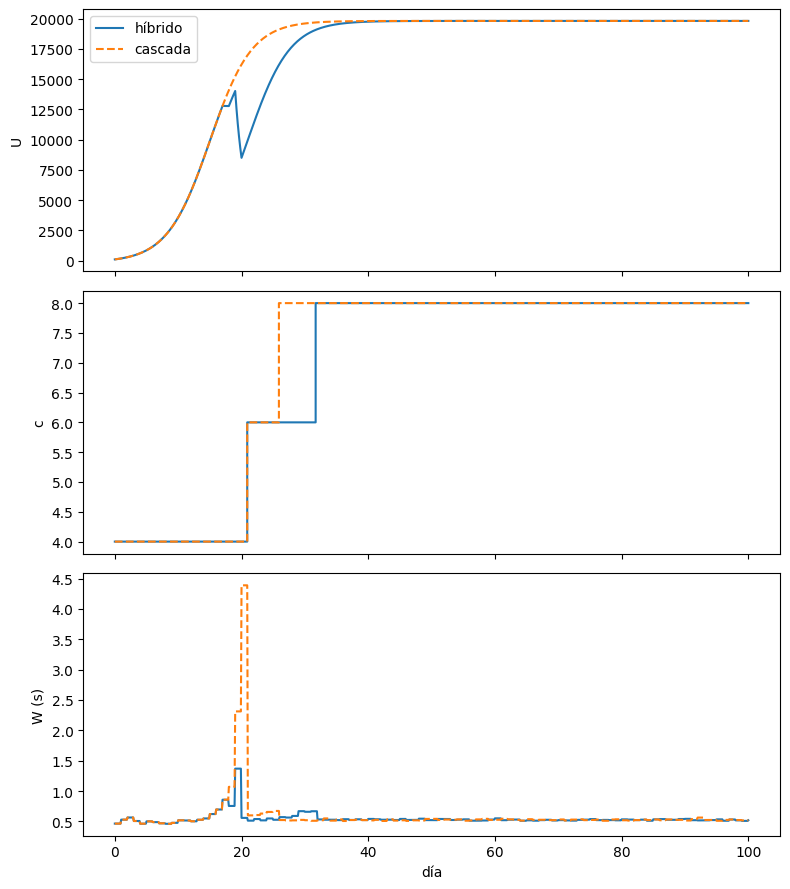

In [2]:
res = correr()
print(f"U(100)              = {res['U'][-1]:.1f}")
print(f"Servidores finales  = {res['c'][-1]}")
print(f"Latencia máxima     = {res['W'].max():.3f} s")
print(f"Rechazo máximo      = {res['r'].max():.4f}")
print(f"Pedidos (día)       = {[round(x, 1) for x in res['pedidos']]}")

casc = correr(feedback=False)
print("\nCascada (kW = kR = 0):")
print(f"U(100) = {casc['U'][-1]:.1f}, c = {casc['c'][-1]}, "
      f"Wmax = {casc['W'].max():.3f} s, rmax = {casc['r'].max():.4f}")
print(f"Pedidos (día) = {[round(x, 1) for x in casc['pedidos']]}")

try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(3, 1, figsize=(8, 9), sharex=True)
    ax[0].plot(res['t'], res['U'], label="híbrido"); ax[0].plot(casc['t'], casc['U'], "--", label="cascada")
    ax[0].set_ylabel("U"); ax[0].legend()
    ax[1].step(res['t'], res['c'], where="post"); ax[1].step(casc['t'], casc['c'], "--", where="post")
    ax[1].set_ylabel("c")
    ax[2].plot(res['t'], res['W']); ax[2].plot(casc['t'], casc['W'], "--")
    ax[2].set_ylabel("W (s)"); ax[2].set_xlabel("día")
    plt.tight_layout(); plt.savefig("hibrido_resultados.png", dpi=120); plt.show()
except ImportError:
    pass
